# Demo: plotly

> **Wie hängen Wohlstand und Lebenserwartung im Jahr 2007 zusammen, und welche Länder oder Regionen fallen aus dem allgemeinen Muster heraus?**

## 0. Vorbereitung

Die Installationszelle ist nur erforderlich, wenn ein Import fehlschlägt. Das Notebook verwendet den in Plotly enthaltenen Gapminder-Datensatz.

In [49]:
# Bei Bedarf das Kommentarzeichen entfernen und die Zelle einmal ausführen:
# %pip install plotly pandas plotnine

In [50]:
import copy
import json
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotnine as p9
from IPython.display import display, Markdown

In [ ]:
# Gapminder Daten aus plotly.express laden
df = px.data.gapminder()

# Auswahl eines bestimmten Jahres, z. B. 2007
year = 2007
df_2007 = df.loc[df["year"] == year].copy()

required = {"country", "continent", "year", "lifeExp", "pop", "gdpPercap"}
assert required.issubset(df.columns)
assert len(df_2007) == df["country"].nunique()

print(f"{len(df_2007)} Länder im Jahr {year}")
print(f"Datenzeitraum: {df['year'].min()}–{df['year'].max()}, Beobachtungen in Fünfjahresschritten")

# Blick auf die Datenstruktur
df_2007.head()

142 Länder im Jahr 2007
Datenzeitraum: 1952–2007, Beobachtungen in Fünfjahresschritten


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
11,Afghanistan,Asia,2007,43.828,31889923,974.580338,AFG,4
23,Albania,Europe,2007,76.423,3600523,5937.029526,ALB,8
35,Algeria,Africa,2007,72.301,33333216,6223.367465,DZA,12
47,Angola,Africa,2007,42.731,12420476,4797.231267,AGO,24
59,Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32


---
## 1. Einstieg: zunächst eine statische Grafik

Die statische Grafik beantwortet bereits die Hauptfrage. Die logarithmische X-Achse verhindert, dass Länder mit niedrigem BIP pro Kopf am linken Rand zusammengedrängt werden. Farbe kodiert den Kontinent.

**Frage an die Studierenden vor der Anzeige:** Welche Muster und Ausnahmen erwarten Sie?

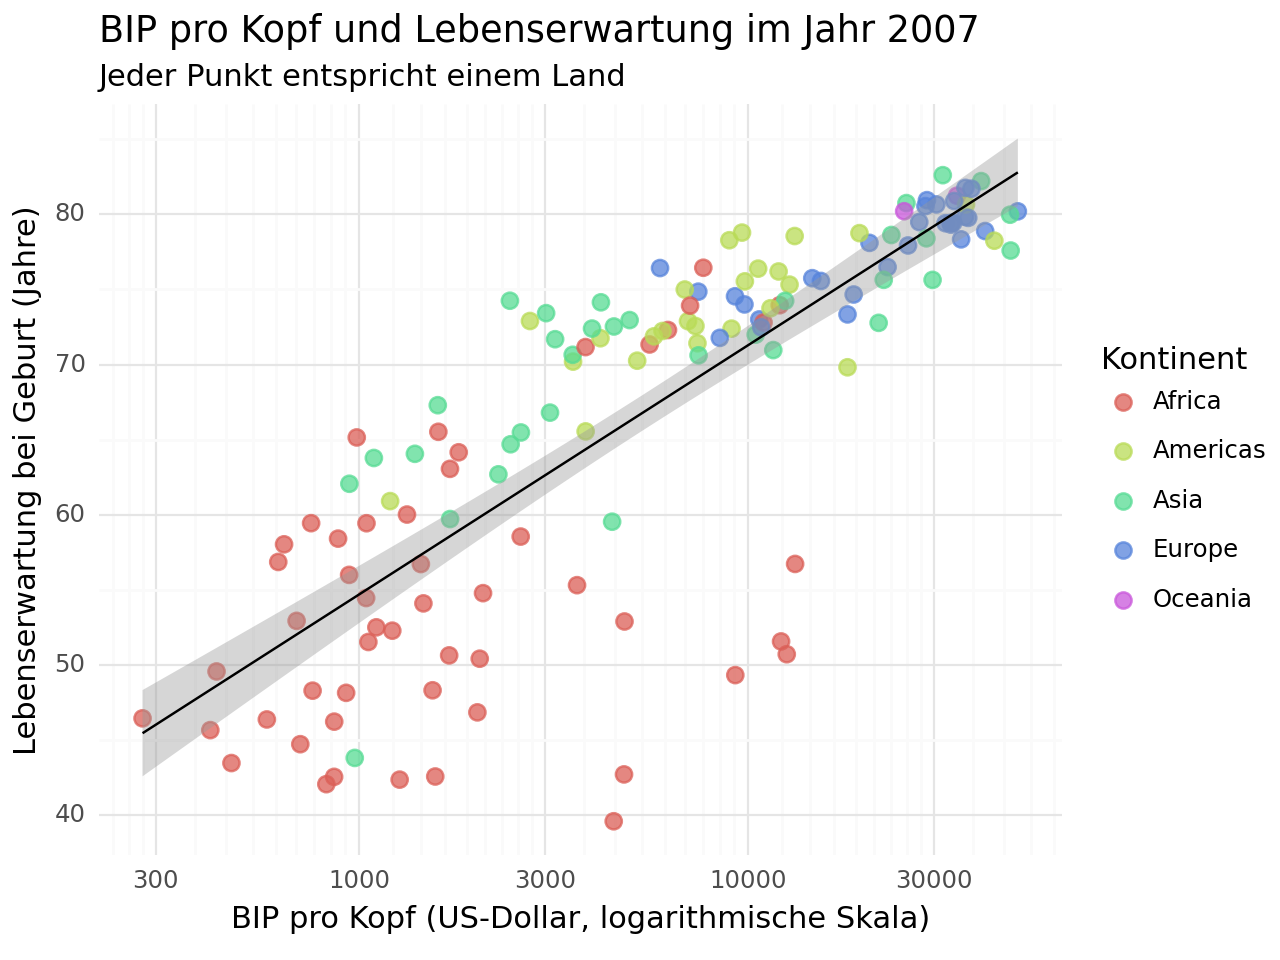

<Figure Size: (640 x 480)>

In [ ]:
static_plot = (
    p9.ggplot(df_2007, p9.aes(
        x="gdpPercap", 
        y="lifeExp", 
        color="continent"))
    + p9.geom_point(alpha=0.75, size=2.8)
    + p9.scale_x_log10()
    + p9.geom_smooth(method="lm", color="black", size=0.5)
    + p9.labs(
        title="BIP pro Kopf und Lebenserwartung im Jahr 2007",
        subtitle="Jeder Punkt entspricht einem Land",
        x="BIP pro Kopf (US-Dollar, logarithmische Skala)",
        y="Lebenserwartung bei Geburt (Jahre)",
        color="Kontinent",
    )
)
static_plot

### Was ist bereits erkennbar?

- Länder mit höherem BIP pro Kopf weisen meist eine höhere Lebenserwartung auf. 
- Einzelne Punkte fallen auf, lassen sich ohne Beschriftung jedoch nicht sicher identifizieren.

Genau an dieser letzten Grenze setzen wir mit Interaktion an.

---
## 2. Schrittweise Erweiterung: Hover

Die visuelle Kodierung bleibt gleich. Hover ergänzt Details, die nicht dauerhaft in der Grafik stehen müssen: Land, Bevölkerung, BIP pro Kopf und Lebenserwartung.

In [53]:
fig_hover = px.scatter(
    df_2007,
    x="gdpPercap",
    y="lifeExp",
    color="continent",
    hover_name="country",
    hover_data={"pop": ":,", "gdpPercap": ":,.0f", "lifeExp": ":.1f", "year": True},
    log_x=True,
    labels={
        "gdpPercap": "BIP pro Kopf (US-Dollar)",
        "lifeExp": "Lebenserwartung (Jahre)",
        "continent": "Kontinent",
        "pop": "Bevölkerung",
        "year": "Jahr",
    },
    title="BIP pro Kopf und Lebenserwartung im Jahr 2007",
)
fig_hover.show()

## 2.1 Zoom und Pan

Plotly stellt **Zoom** und **Pan** über die **Modebar** bereit. 

Mit `dragmode="zoom"` ist das Aufziehen eines Bereichs die Standardgeste; `scrollZoom` aktiviert zusätzlich das Mausrad. Ein Doppelklick setzt die Ansicht zurück.

**Demoauftrag:** Zoomen Sie in eine dichte Punktgruppe. Was wird klarer, und welcher Kontext geht verloren?

In [54]:
# Kopie der Abbildung erstellen, um den Zoommodus zu aktivieren, ohne die ursprüngliche Abbildung zu verändern
fig_zoom = copy.deepcopy(fig_hover)

# Zoommodus zusätzlich aktivieren  
fig_zoom.update_layout(
    dragmode="zoom",
    title="Zoom: lokale Details untersuchen, Kontext bewusst erhalten",
)
fig_zoom.show(config={"scrollZoom": True, "displaylogo": False})

## 2.2 Filtern über die Legende

Da Plotly Express für jeden Kontinent einen eigenen **Trace** erzeugt, funktioniert die **Legende** als einfacher **Filter**:

- Klick blendet einen Kontinent ein oder aus.
- Doppelklick isoliert einen Kontinent.
- Ein weiterer Doppelklick stellt alle Traces wieder her.

Damit kann dieselbe Grafik sowohl den Überblick als auch eine fokussierte Teilansicht zeigen.

In [ ]:
fig_legend = copy.deepcopy(fig_hover)
fig_legend.update_layout(
    title="Filter: Kontinente über die Legende ein- und ausblenden",
    legend_title_text="Kontinent – klicken zum Filtern",
)
fig_legend.show(config={"displaylogo": False})

---
## 3. Shneidermans Mantra

> **Overview first, zoom and filter, then details-on-demand.**


| Beobachtete Handlung | Funktion in der Analyse | Teil des Mantras |
|---|---|---|
| Alle Länder und Kontinente erscheinen zuerst | Gesamtmuster und Ausnahmen erkennen | **Overview first** |
| Zoomen, Legendenklick oder später Dropdown | Datenraum auf eine Frage eingrenzen | **Zoom and filter** |
| Hover über ein einzelnes Land | Werte und Identität gezielt abrufen | **Details-on-demand** |

Das Mantra beschreibt keine starre Abfolge für jede Anwendung. Es formuliert eine hilfreiche Standarddramaturgie für explorative Visualisierungen.

---
## 4. Interaktionstypen in einer kompakten Matrix

| Interaktion | Nutzerfrage | Typische Umsetzung | Nutzen | Hauptrisiko |
|---|---|---|---|---|
| Hover / Tooltip | Welcher Punkt ist das? | `hover_name`, `hover_data`, `hovertemplate` | Details ohne dauerhafte Beschriftung | zentrale Information bleibt verborgen |
| Zoom / Pan | Was passiert in diesem Ausschnitt? | Modebar, `dragmode`, Range Slider | dichte Bereiche untersuchen | Kontextverlust |
| Filter | Wie sieht eine Teilgruppe aus? | Legende, Dropdown, Slider | Komplexität reduzieren | Filterzustand wird übersehen |
| Selektion | Welche Elemente interessieren mich? | Klick, Box- oder Lasso-Auswahl | Fälle gezielt markieren | unklare Auswahlrückmeldung |
| Koordinierte Ansichten | Wie hängt ein Fall in mehreren Darstellungen zusammen? | gemeinsamer Filter oder Callback | mehrere Perspektiven verbinden | technische und kognitive Komplexität |
| Animation* | Wie verändert sich das Muster? | `animation_frame`, `frames` | zeitlichen Verlauf zeigen | Vergleiche zwischen Frames sind schwer |
| Export / Teilen | Wie kann ich das Ergebnis weiterverwenden? | Modebar, HTML, Bildexport | Kommunikation und Reproduzierbarkeit | Interaktivität geht beim statischen Export verloren |

\* Animation vertiefen wir in einer weiteren Vorlesung

---
## 5. Das Plotly-Figure-Modell: `data`, `layout`, `frames`

Eine Plotly-Figur ist eine verschachtelte, JSON-kompatible Struktur:

- **`data`** enthält die Traces: Punkte, Linien, Balken oder andere grafische Markierungen.
- **`layout`** enthält Achsen, Titel, Legende, Annotationen und Steuerelemente.
- **`frames`** enthält optionale Zustände einer Animation.

Plotly Express erzeugt ein vollständig befülltes `go.Figure`-Objekt. `update_*` verändert dieses Objekt anschließend.

In [56]:
figure_summary = {
    "data": [
        {"index": i, "type": trace.type, "name": trace.name, "points": len(trace.x)}
        for i, trace in enumerate(fig_hover.data)
    ],
    "layout": {
        "title": fig_hover.layout.title.text,
        "xaxis_type": fig_hover.layout.xaxis.type,
        "legend_title": fig_hover.layout.legend.title.text,
    },
    "frames": len(fig_hover.frames),
}
print(json.dumps(figure_summary, indent=2, ensure_ascii=False))

{
  "data": [
    {
      "index": 0,
      "type": "scatter",
      "name": "Asia",
      "points": 33
    },
    {
      "index": 1,
      "type": "scatter",
      "name": "Europe",
      "points": 30
    },
    {
      "index": 2,
      "type": "scatter",
      "name": "Africa",
      "points": 52
    },
    {
      "index": 3,
      "type": "scatter",
      "name": "Americas",
      "points": 25
    },
    {
      "index": 4,
      "type": "scatter",
      "name": "Oceania",
      "points": 2
    }
  ],
  "layout": {
    "title": "BIP pro Kopf und Lebenserwartung im Jahr 2007",
    "xaxis_type": "log",
    "legend_title": "Kontinent"
  },
  "frames": 0
}


### Frames sichtbar machen

Eine Animation beantwortet eine neue Frage: Wie verändert sich der Zusammenhang über die Zeit? Für die heutige Leitfrage ist sie nicht zwingend nötig, erklärt aber die Rolle von `frames`.

In [57]:
# Datenbereich 
x_min = df["gdpPercap"].min() * 0.95
y_min = df["lifeExp"].min() * 0.95
x_max = df["gdpPercap"].max() * 1.05
y_max = df["lifeExp"].max() * 1.05

# Animation über die Jahre
fig_animation = px.scatter(
    df, x="gdpPercap", y="lifeExp", animation_frame="year", animation_group="country",
    size="pop", color="continent", hover_name="country", log_x=True, size_max=50,
    range_x=[x_min, x_max], range_y=[y_min, y_max],
    labels={"gdpPercap": "BIP pro Kopf (US-Dollar)", "lifeExp": "Lebenserwartung (Jahre)"},
    title="Gapminder im Zeitverlauf",
)

print(f"Traces im Ausgangszustand: {len(fig_animation.data)}")
print(f"Frames der Animation: {len(fig_animation.frames)}")
fig_animation.show(config={"displaylogo": False})

Traces im Ausgangszustand: 5
Frames der Animation: 12


---
## 6. Plotly Express entwickeln und mit `update_*` verfeinern

Wir erzeugen die Figur zunächst kompakt mit **Plotly Express**. 

Danach trennen wir die Änderungen nach Zuständigkeit:

- `update_traces`: Markierungen und Hover-Inhalte
- `update_layout`: Titel, Legende, Abstände und globale Darstellung
- `update_xaxes` / `update_yaxes`: Achsen und Gitterlinien

In [44]:
# Plotly Express bietet eine einfache Möglichkeit, die Darstellung der Punkte zu aktualisieren, ohne die ursprüngliche Abbildung zu verändern. Hier wird eine neue Abbildung erstellt, die die Punkte größer und transparenter darstellt und ein benutzerdefiniertes Hover-Template verwendet.
fig_updated = px.scatter(
    df_2007, x="gdpPercap", y="lifeExp", color="continent", hover_name="country", log_x=True
)

# Die Darstellung der Punkte wird aktualisiert, um sie größer und transparenter zu machen, und ein benutzerdefiniertes Hover-Template wird hinzugefügt.
fig_updated.update_traces(
    marker={"size": 10, "opacity": 0.78, "line": {"width": 0.6, "color": "white"}},
    hovertemplate="<b>%{hovertext}</b><br>BIP/Kopf: %{x:,.0f} US$<br>Lebenserwartung: %{y:.1f} Jahre<extra></extra>",
)

# Die Layout-Einstellungen der Abbildung werden aktualisiert, um den Titel, das Template, die Legende, die Ränder und den Hover-Modus anzupassen. Außerdem werden die Achsentitel und der Bereich der y-Achse festgelegt.
fig_updated.update_layout(
    title={"text": "Wohlstand und Lebenserwartung im Jahr 2007", "x": 0.02},
    template="plotly_white",
    legend={"title": {"text": "Kontinent"}, "orientation": "h", "y": 1.12},
    margin={"l": 70, "r": 30, "t": 110, "b": 70},
    hovermode="closest",
)

# Die Achsentitel und der Bereich der y-Achse werden aktualisiert, um die Daten besser darzustellen.
fig_updated.update_xaxes(title="BIP pro Kopf (US-Dollar, Log-Skala)", showgrid=True)
fig_updated.update_yaxes(title="Lebenserwartung bei Geburt (Jahre)", range=[35, 85], showgrid=True)
 
fig_updated.show(config={"displaylogo": False})

---
## 7. Vollständiges Dropdown-Mikrobeispiel

`color="continent"` erzeugt einen Trace je Kontinent. Jeder Dropdown-Button setzt eine boolesche `visible`-Liste in exakt dieser Trace-Reihenfolge. `method="update"` verändert gleichzeitig Trace-Eigenschaften und den Titel im Layout.

In [45]:
# Die Abbildung wird kopiert, um die Interaktionen zu aktualisieren
fig_dropdown = copy.deepcopy(fig_updated)

# Die Namen der Traces werden extrahiert, um die Dropdown-Buttons zu erstellen.
trace_names = [trace.name for trace in fig_dropdown.data]

# Die Dropdown-Buttons werden erstellt, um die Sichtbarkeit der Traces basierend auf dem ausgewählten Kontinent zu steuern. Der erste Button zeigt alle Kontinente an, während die folgenden Buttons jeweils einen einzelnen Kontinent anzeigen.
buttons = [
    dict(
        label="Alle Kontinente",
        method="update",
        args=[
            {"visible": [True] * len(fig_dropdown.data)},
            {"title.text": "Wohlstand und Lebenserwartung – alle Kontinente"},
        ],
    )
]

# Die Sichtbarkeit der Traces wird für jeden Kontinent aktualisiert, und die entsprechenden Dropdown-Buttons werden erstellt. 
for continent in trace_names:
    visibility = [name == continent for name in trace_names]
    buttons.append(
        dict(
            label=continent,
            method="update",
            args=[
                {"visible": visibility},
                {"title.text": f"Wohlstand und Lebenserwartung – {continent}"},
            ],
        )
    )

# Die Layout-Einstellungen der Abbildung werden aktualisiert, um das Dropdown-Menü hinzuzufügen und die Ränder anzupassen.
fig_dropdown.update_layout(
    updatemenus=[
        dict(
            type="dropdown", buttons=buttons, active=0, showactive=True,
            x=0.0, xanchor="left", y=1.25, yanchor="top",
        )
    ],
    margin={"l": 70, "r": 30, "t": 145, "b": 70},
)
fig_dropdown.show(config={"displaylogo": False})

### Gemeinsame Code-Lesefragen

1. Warum muss `visibility` genauso viele Werte wie `fig_dropdown.data` enthalten?
2. Warum verwenden wir `update` statt nur `restyle`?
3. Wo wird der aktive Filterzustand sichtbar?
4. Welche Reset-Möglichkeit bietet das Dropdown?

---
## 8. Koordinierte Mehrfachansicht

Der Scatterplot zeigt einen bivariaten Zusammenhang. Das Histogramm zeigt gleichzeitig die Verteilung der Lebenserwartung. Ein gemeinsamer Kontinentfilter aktualisiert beide Ansichten.

> Dies ist **koordinierte Filterung**. Echtes Brushing & Linking würde eine direkte Punktselektion in einer Ansicht in der anderen Ansicht hervorheben und benötigt zusätzliche Ereignislogik, etwa in Dash oder mit `FigureWidget`.

In [ ]:
# Filterung der Daten nach Kontinenten für die koordinierte Ansicht
filters = {"Alle Kontinente": df_2007}

# Aktualisierung der Filter, um die Daten für jeden Kontinent zu speichern. Die Filter werden in einem Dictionary gespeichert, wobei der Schlüssel der Name des Kontinents ist und der Wert ein DataFrame mit den entsprechenden Daten ist.
filters.update({
    continent: df_2007.loc[df_2007["continent"] == continent]
    for continent in sorted(df_2007["continent"].unique())
})

# Die Abbildung wird erstellt, die die BIP pro Kopf und Lebenserwartung in einem Scatter-Plot sowie die Verteilung der Lebenserwartung in einem Histogramm darstellt. Die beiden Plots sind miteinander verknüpft, sodass die Auswahl eines Kontinents in der Dropdown-Liste beide Plots gleichzeitig aktualisiert.
fig_linked = make_subplots(
    rows=1, cols=2, column_widths=[0.62, 0.38], horizontal_spacing=0.12,
    subplot_titles=("BIP pro Kopf und Lebenserwartung", "Verteilung der Lebenserwartung"),
)

# Linking: Die Scatter-Plot-Trace wird zur Abbildung hinzugefügt, um die BIP pro Kopf und Lebenserwartung der Länder im Jahr 2007 darzustellen. Die Punkte sind blau, halbtransparent und haben eine Größe von 9. Ein benutzerdefiniertes Hover-Template zeigt den Ländernamen, das BIP pro Kopf und die Lebenserwartung an.
fig_linked.add_trace(
    go.Scatter(
        x=df_2007["gdpPercap"], 
        y=df_2007["lifeExp"], 
        text=df_2007["country"],
        mode="markers", name="Länder", marker={"size": 9, "opacity": 0.75, "color": "#334ACC"},
        hovertemplate="<b>%{text}</b><br>BIP/Kopf: %{x:,.0f} US$<br>Lebenserwartung: %{y:.1f} Jahre<extra></extra>",
    ), row=1, col=1,
)

# Linking: Die Histogramm-Trace wird zur Abbildung hinzugefügt, um die Verteilung der Lebenserwartung der Länder im Jahr 2007 darzustellen. Das Histogramm hat 12 Bins und ist rot gefärbt. Ein benutzerdefiniertes Hover-Template zeigt die Lebenserwartung und die Anzahl der Länder in jedem Intervall an.
fig_linked.add_trace(
    go.Histogram(
        x=df_2007["lifeExp"], nbinsx=20, name="Verteilung", marker_color="#DC3912",
        hovertemplate="Lebenserwartung: %{x}<br>Länder im Intervall: %{y}<extra></extra>",
    ), row=1, col=2,
)

# Die Dropdown-Buttons werden erstellt, um die Daten in beiden Plots gleichzeitig zu aktualisieren, wenn ein Kontinent ausgewählt wird. Jeder Button aktualisiert die x- und y-Daten der Scatter-Plot-Trace sowie die x-Daten der Histogramm-Trace und den Titel der Abbildung.
linked_buttons = []
for label, subset in filters.items():
    linked_buttons.append(
        dict(
            label=label, method="update",
            args=[
                {
                    "x": [subset["gdpPercap"], subset["lifeExp"]],
                    "y": [subset["lifeExp"], None],
                    "text": [subset["country"], None],
                },
                {"title.text": f"Koordinierte Ansichten – {label}"},
            ],
        )
    )

# Die Layout-Einstellungen der Abbildung werden aktualisiert, um den Titel, das Template, die Legende, die Ränder und das Dropdown-Menü anzupassen. Außerdem werden die Achsentitel und der Bereich der y-Achse festgelegt.
fig_linked.update_layout(
    title={"text": "Koordinierte Ansichten – Alle Kontinente", "x": 0.02},
    template="plotly_white", showlegend=False, height=560,
    updatemenus=[dict(buttons=linked_buttons, active=0, x=0, y=1.22, xanchor="left", yanchor="top")],
    margin={"l": 70, "r": 30, "t": 135, "b": 70},
)

# Die Achsentitel und der Bereich der y-Achse werden aktualisiert, um die Daten besser darzustellen. 
fig_linked.update_xaxes(type="log", title="BIP pro Kopf (US-Dollar)", row=1, col=1)
fig_linked.update_yaxes(title="Lebenserwartung (Jahre)", range=[35, 85], row=1, col=1)
fig_linked.update_xaxes(title="Lebenserwartung (Jahre)", range=[35, 85], row=1, col=2)
fig_linked.update_yaxes(title="Anzahl Länder", row=1, col=2)
fig_linked.show(config={"displaylogo": False, "responsive": True})

---
## 9. Gestaltungsgrenzen, Accessibility und Responsiveness

Wir prüfen dieselbe Scatterplot-Idee gegen typische Risiken:

| Risiko | Anpassung in der Demo | Verbleibende Grenze |
|---|---|---|
| Farbe ist nicht für alle gleich unterscheidbar | Kontinent zusätzlich über Symbol kodieren | mehr visuelle Komplexität |
| Hover ist auf Touchgeräten oder per Tastatur schwer erreichbar | Kernmuster bleibt in Titel, Achsen und Legende sichtbar; Datentabelle ergänzen | vollständige Tastatur- und Screenreader-Nutzung ist nicht garantiert |
| Kleine Displays führen zu Überlagerungen | horizontale Legende, automatische Ränder, responsive Konfiguration | komplexe Mehrfachansichten brauchen oft ein alternatives mobiles Layout |
| Zoom kann Kontext entfernen | aussagekräftige Startansicht und Reset per Doppelklick | Nutzer können gefilterten Zustand übersehen |
| Zu viele Interaktionen überfordern | nur Hover, Zoom und einen Filter anbieten | andere Analysefragen benötigen andere Werkzeuge |

In [47]:
# Farbe und Symbol kodieren den Kontinent
accessible_colors = px.colors.qualitative.Safe

# Scatter-Plot wird erstellt, der die BIP pro Kopf und Lebenserwartung im Jahr 2007 darstellt. Die Punkte sind nach Kontinenten farblich und symbolisch kodiert, um die Unterschiede zwischen den Kontinenten hervorzuheben. Ein benutzerdefiniertes Hover-Template zeigt den Ländernamen, das BIP pro Kopf, die Lebenserwartung und die Bevölkerung an.
fig_accessible = px.scatter(
    df_2007, x="gdpPercap", y="lifeExp",
    color="continent", symbol="continent",
    color_discrete_sequence=accessible_colors,
    hover_name="country",
    hover_data={"pop": ":,", "gdpPercap": ":,.0f", "lifeExp": ":.1f"},
    log_x=True,
    labels={
        "gdpPercap": "BIP pro Kopf (US-Dollar)",
        "lifeExp": "Lebenserwartung bei Geburt (Jahre)",
        "continent": "Kontinent",
        "pop": "Bevölkerung",
    },
    title="Wohlstand und Lebenserwartung 2007 – Farbe und Symbol kodieren den Kontinent",
)

# Die Darstellung der Punkte wird aktualisiert, um sie größer und transparenter zu machen, und ein benutzerdefiniertes Hover-Template wird hinzugefügt.
fig_accessible.update_traces(marker={"size": 11, "opacity": 0.82, "line": {"width": 0.7, "color": "white"}})
fig_accessible.update_layout(
    template="plotly_white", autosize=True, height=560,
    font={"size": 14},
    legend={"orientation": "h", "y": 1.14, "title": {"text": "Kontinent – Farbe und Symbol"}},
    margin={"l": 75, "r": 25, "t": 120, "b": 70},
)
fig_accessible.update_xaxes(automargin=True)
fig_accessible.update_yaxes(automargin=True, range=[35, 85])
fig_accessible.show(config={"responsive": True, "displaylogo": False})

### Die passende Tabelle zur Grafik bereitstellen

Für eine veröffentlichte Anwendung sollte neben der interaktiven Grafik mindestens eine Textzusammenfassung und bei Bedarf eine zugängliche Datentabelle angeboten werden. 

Die Tabelle ist kein dekorativer Zusatz, sondern eine alternative Form des Datenzugangs.

In [48]:
summary_table = (
    df_2007[["country", "continent", "gdpPercap", "lifeExp", "pop"]]
    .sort_values(["lifeExp"], ascending=[False])
    .rename(columns={
        "country": "Land", "continent": "Kontinent",
        "lifeExp": "Lebenserwartung (Jahre)",
        "pop": "Bevölkerung",
        "gdpPercap": "BIP pro Kopf (US$)",
    })
)

print("Top 5/Bottom 5 Länder nach Lebenserwartung im Jahr 2007:")
display(summary_table.head(5).style.format({
    "Lebenserwartung (Jahre)": "{:.1f}",
    "Bevölkerung": "{:,.0f}",
    "BIP pro Kopf (US$)": "{:,.0f}",
}))

display(summary_table.tail(5).style.format({
    "Lebenserwartung (Jahre)": "{:.1f}",
    "Bevölkerung": "{:,.0f}",
    "BIP pro Kopf (US$)": "{:,.0f}",
    }))

Top 5/Bottom 5 Länder nach Lebenserwartung im Jahr 2007:


,Land,Kontinent,BIP pro Kopf (US$),Lebenserwartung (Jahre),Bevölkerung
803,Japan,Asia,"31,656",82.6,"127,467,972"
671,"Hong Kong, China",Asia,"39,725",82.2,"6,980,412"
695,Iceland,Europe,"36,181",81.8,"301,931"
1487,Switzerland,Europe,"37,506",81.7,"7,554,661"
71,Australia,Oceania,"34,435",81.2,"20,434,176"


,Land,Kontinent,BIP pro Kopf (US$),Lebenserwartung (Jahre),Bevölkerung
887,Lesotho,Africa,"1,569",42.6,"2,012,649"
1355,Sierra Leone,Africa,863,42.6,"6,144,562"
1691,Zambia,Africa,"1,271",42.4,"11,746,035"
1043,Mozambique,Africa,824,42.1,"19,951,656"
1463,Swaziland,Africa,"4,513",39.6,"1,133,066"


---

## Abschluss: Was hat die Interaktion geleistet?

1. **Statische Grafik:** Das Gesamtmuster war bereits sichtbar.
2. **Hover:** Einzelne Länder ließen sich identifizieren, ohne alle Punkte zu beschriften.
3. **Zoom:** Dichte Bereiche wurden untersuchbar, allerdings mit möglichem Kontextverlust.
4. **Filter:** Kontinente konnten gezielt verglichen und wieder in den Gesamtüberblick eingeordnet werden.
5. **Koordinierte Ansichten:** Zusammenhang und Verteilung wurden gemeinsam lesbar.
6. **Accessibility und Responsiveness:** Gute Interaktion benötigt alternative Kodierungen, verständliche Standardansichten und zusätzliche Zugangsformen.


> Interaktivität ist dann sinnvoll, wenn sie eine konkrete Nutzerfrage leichter beantwortbar macht. Sie ersetzt weder eine klare visuelle Kodierung noch eine verständliche Kernaussage.